<a href="https://colab.research.google.com/github/jaquespires77-afk/Econometrics-foundations/blob/main/aula17_efeitos_fixos_aleatorios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

rng = np.random.default_rng(17)

registros = []

for i in range(78):
    municipio = f"ES_{i:02d}"

    # Característica municipal não observada
    alpha = rng.normal(0, 2)

    erro_anterior = 0

    for ano in range(2016, 2026):

        # Atividade correlacionada com alpha
        atividade = (
            0.8 * alpha
            + rng.normal(0, 1.5)
        )

        # Erro com persistência temporal
        erro = (
            0.5 * erro_anterior
            + rng.normal(0, 1)
        )

        emprego = (
            10
            + 2 * atividade
            + 3 * alpha
            + erro
        )

        registros.append({
            "municipio": municipio,
            "ano": ano,
            "atividade": atividade,
            "emprego": emprego
        })

        erro_anterior = erro

dados = pd.DataFrame(registros)

print(dados.head())
print("Observações:", len(dados))


  municipio   ano  atividade    emprego
0     ES_00  2016   2.269667  20.606937
1     ES_00  2017  -0.128343  14.186282
2     ES_00  2018   1.789977  18.294659
3     ES_00  2019   0.453786  16.346742
4     ES_00  2020   1.684251  17.115091
Observações: 780


Observe a construção do experimento.

O verdadeiro coeficiente da atividade é:   

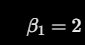

Entretanto, a variável atividade está correlacionada com alpha, que também influencia o emprego.

Criamos deliberadamente uma situação em que a omissão de características municipais pode gerar viés.

Etapa 2 — Estimar Pooled OLS

In [ ]:

pooled = smf.ols(
    "emprego ~ atividade",
    data=dados
).fit(
    cov_type="cluster",
    cov_kwds={"groups": dados["municipio"]}
)

print(pooled.params["atividade"])


4.0603399905461295


Esse modelo ignora as diferenças permanentes não observadas entre municípios.

Como introduzimos correlação entre atividade e alpha, esperamos que a estimativa agrupada se afaste do verdadeiro coeficiente 2.

Etapa 3 — Aplicar manualmente a transformação within

In [ ]:

dados["atividade_within"] = (
    dados["atividade"]
    - dados.groupby("municipio")["atividade"]
           .transform("mean")
)

dados["emprego_within"] = (
    dados["emprego"]
    - dados.groupby("municipio")["emprego"]
           .transform("mean")
)

within = sm.OLS(
    dados["emprego_within"],
    dados[["atividade_within"]]
).fit(
    cov_type="cluster",
    cov_kwds={"groups": dados["municipio"]}
)

print("Coeficiente within:")
print(within.params["atividade_within"])


Coeficiente within:
1.9752298197325304


Observe que não incluímos intercepto na regressão das variáveis transformadas.

A transformação já eliminou os interceptos individuais.

Etapa 4 — Confirmar o resultado com efeitos fixos

In [ ]:

efeitos_fixos = smf.ols(
    "emprego ~ atividade + C(municipio)",
    data=dados
).fit(
    cov_type="cluster",
    cov_kwds={"groups": dados["municipio"]}
)

print("Pooled:", pooled.params["atividade"])

print(
    "Within:",
    within.params["atividade_within"]
)

print(
    "Efeitos fixos:",
    efeitos_fixos.params["atividade"]
)


Pooled: 4.0603399905461295
Within: 1.9752298197325304
Efeitos fixos: 1.9752298197325366


O que devemos verificar?

O coeficiente obtido pela transformação within deve coincidir, até diferenças numéricas de arredondamento, com o coeficiente da regressão que inclui indicadores municipais.

Essa é uma aplicação direta da lógica do teorema de Frisch–Waugh–Lovell.

Os erros-padrão podem apresentar diferenças entre implementações devido aos ajustes de graus de liberdade utilizados.

Etapa 5 — Estimar FE e RE com linearmodels
No Colab, instale o pacote:

%pip install -q linearmodels

In [ ]:
%pip install -q linearmodels

Execute

In [ ]:

from linearmodels.panel import PanelOLS, RandomEffects

painel = dados.set_index(
    ["municipio", "ano"]
)

# Efeitos fixos municipais
modelo_fe = PanelOLS.from_formula(
    "emprego ~ 1 + atividade + EntityEffects",
    data=painel
).fit(
    cov_type="clustered",
    cluster_entity=True
)

# Efeitos aleatórios convencionais
modelo_re = RandomEffects.from_formula(
    "emprego ~ 1 + atividade",
    data=painel
).fit(
    cov_type="clustered",
    cluster_entity=True
)

print("FE:", modelo_fe.params["atividade"])
print("RE:", modelo_re.params["atividade"])

print(modelo_fe.summary)
print(modelo_re.summary)


FE: 1.9752298197325284
RE: 2.13008037312051
                          PanelOLS Estimation Summary                           
Dep. Variable:                emprego   R-squared:                        0.8884
Estimator:                   PanelOLS   R-squared (Between):              0.5815
No. Observations:                 780   R-squared (Within):               0.8884
Date:                Sat, Nov 14 2026   R-squared (Overall):              0.6070
Time:                        10:10:09   Log-likelihood                   -1096.4
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      5577.7
Entities:                          78   P-value                           0.0000
Avg Obs:                      10.0000   Distribution:                   F(1,701)
Min Obs:                      10.0000                                           
Max Obs:                      10.0000   F-statistic (robust):    

Etapa 6 — Construir a comparação

In [ ]:

comparacao = pd.DataFrame({
    "Estimador": [
        "Pooled OLS",
        "Efeitos fixos",
        "Efeitos aleatórios"
    ],
    "Coeficiente": [
        pooled.params["atividade"],
        modelo_fe.params["atividade"],
        modelo_re.params["atividade"]
    ],
    "Erro-padrao": [
        pooled.bse["atividade"],
        modelo_fe.std_errors["atividade"],
        modelo_re.std_errors["atividade"]
    ]
})

comparacao["Distancia_do_verdadeiro"] = (
    comparacao["Coeficiente"] - 2
)

print(comparacao.round(4))


            Estimador  Coeficiente  Erro-padrao  Distancia_do_verdadeiro
0          Pooled OLS       4.0603       0.1954                   2.0603
1       Efeitos fixos       1.9752       0.0258                  -0.0248
2  Efeitos aleatórios       2.1301       0.0383                   0.1301


O objetivo é comparar as estimativas com o parâmetro verdadeiro, que conhecemos por se tratar de uma simulação.

Não devemos pressupor que FE produzirá exatamente 2. Em uma amostra finita, existe variabilidade amostral.

Também não devemos julgar um estimador apenas por uma simulação. Posteriormente, utilizaremos experimentos de Monte Carlo para investigar viés, variância e erro quadrático médio em muitas amostras.

Extensão opcional — Efeitos fixos de município e ano

Para incluir também efeitos temporais:

In [ ]:

modelo_twfe = PanelOLS.from_formula(
    "emprego ~ 1 + atividade + EntityEffects + TimeEffects",
    data=painel
).fit(
    cov_type="clustered",
    cluster_entity=True
)

print(modelo_twfe.summary)


                          PanelOLS Estimation Summary                           
Dep. Variable:                emprego   R-squared:                        0.8884
Estimator:                   PanelOLS   R-squared (Between):              0.5812
No. Observations:                 780   R-squared (Within):               0.8884
Date:                Sat, Nov 14 2026   R-squared (Overall):              0.6067
Time:                        10:10:09   Log-likelihood                   -1093.0
Cov. Estimator:             Clustered                                           
                                        F-statistic:                      5508.2
Entities:                          78   P-value                           0.0000
Avg Obs:                      10.0000   Distribution:                   F(1,692)
Min Obs:                      10.0000                                           
Max Obs:                      10.0000   F-statistic (robust):             4949.5
                            

Neste experimento, não introduzimos choques de ano compartilhados na geração dos dados.


 A extensão serve para praticar a especificação com efeitos fixos em duas dimensões.